# 02 — Limpieza, split temporal y features
## Proyecto final de Machine Learning — Grupo 11 · Lending Club

**Objetivo:** dejar listo el conjunto de datos para modelar, con tres decisiones documentadas:
1. **Split temporal** confiable (evitando censura por la derecha).
2. **Limpieza** por reglas de dominio y tratamiento de outliers sin filtrar información del futuro.
3. **Ingeniería de variables** y preprocesador de sklearn ajustado **solo con train**.

La lógica reutilizable vive en `src/data.py`, `src/features.py` y `src/config.py`; este notebook la usa y explica.


In [15]:
import sys
from pathlib import Path

# El notebook vive en notebooks/; la raíz del repo es el directorio padre
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, data, features

sns.set_theme(style="whitegrid")
np.random.seed(config.SEED)
pd.set_option("display.max_columns", 100)


## 1. Carga de datos

In [16]:
df_raw = data.load_raw()
print(f"Filas: {len(df_raw):,} | Columnas: {df_raw.shape[1]}")


Filas: 2,260,701 | Columnas: 27


## 2. Diagnóstico de censura: ¿qué años son confiables?

Un préstamo solo entra al modelo si ya tiene desenlace definitivo (`Fully Paid`, `Charged Off`, `Default`).
Los préstamos recientes (y los de 60 meses) todavía están `Current` en muchos casos, y los que **sí** tienen desenlace
no son una muestra representativa: son los que se pagaron antes de tiempo o cayeron en default rápido.
Esto se llama *censura por la derecha* y sesga la tasa de default hacia abajo o hacia arriba según el año.

La tabla muestra, por año de originación y plazo, cuántos préstamos hay, qué porcentaje ya está resuelto
y la tasa de default entre los resueltos. **Esta tabla se calcula sobre el dataset completo solo para diseñar el split;
no se usa para elegir modelos.**


In [17]:
tabla = data.censoring_table(df_raw)
tabla


n_prestamos  pct_resueltos  tasa_default_resueltos
issue_year term                                                         
2007.0     36 months          603          0.416                   0.179
2008.0     36 months         2393          0.653                   0.158
2009.0     36 months         5281          0.893                   0.126
2010.0     36 months         9156          0.925                   0.099
           60 months         3381          0.908                   0.210
2011.0     36 months        14101          1.000                   0.106
           60 months         7620          1.000                   0.236
2012.0     36 months        43470          1.000                   0.136
           60 months         9897          1.000                   0.277
2013.0     36 months       100422          1.000                   0.123
           60 months        34392          1.000                   0.251
2014.0     36 months       162570          1.000                   0.137
           60 months        73059          0.829                   0.311
2015.0     36 months       283173          0.999                   0.149
           60 months       137922          0.671                   0.364
2016.0     36 months       323495          0.718                   0.198
           60 months       110912          0.548                   0.364
2017.0     36 months       320419          0.401                   0.200
           60 months       123160          0.331                   0.330
2018.0     36 months       344671          0.120                   0.132
           60 months       150571          0.100                   0.226

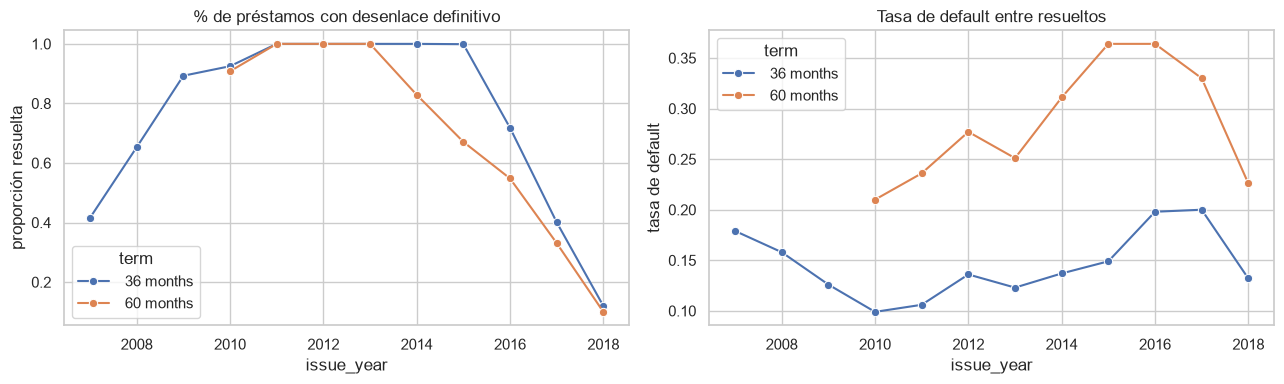

In [18]:
t = tabla.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=t, x="issue_year", y="pct_resueltos", hue="term", marker="o", ax=axes[0])
axes[0].set_title("% de préstamos con desenlace definitivo")
axes[0].set_ylabel("proporción resuelta")
sns.lineplot(data=t, x="issue_year", y="tasa_default_resueltos", hue="term", marker="o", ax=axes[1])
axes[1].set_title("Tasa de default entre resueltos")
axes[1].set_ylabel("tasa de default")
plt.tight_layout()
plt.show()


### Decisión del split

Criterio: usar años en los que el porcentaje resuelto sea alto y la tasa de default se vea estable entre plazos.
Los valores vigentes están en `src/config.py`:

| Conjunto | Años de originación | Uso |
|---|---|---|
| Train | `TRAIN_YEARS` (2012–2014) | ajustar modelos y preprocesador |
| Validación | `VALID_YEAR` (2015) | elegir modelo e hiperparámetros |
| Test | `TEST_YEAR` (2016) | **una sola** evaluación final |

> **Completar tras ver la tabla de arriba:** confirmar (o ajustar en `config.py`) estos años y, si el plazo de 60 meses
> sigue muy incompleto en 2015–2016, decidir si se fija `ONLY_TERM = " 36 months"`. Documentar aquí la justificación
> con los números reales de la tabla.


## 3. Target, limpieza por reglas de dominio y variables derivadas

In [19]:
df = data.build_target(df_raw)
df = data.add_issue_year(df)
print(f"Filas con desenlace definitivo: {len(df):,} | tasa de default global: {df['target'].mean():.3f}")

df, reglas = features.clean(df, report=True)
pd.Series(reglas, name="filas afectadas (pasan a NaN)").to_frame()


Filas con desenlace definitivo: 1,345,350 | tasa de default global: 0.200


,filas afectadas (pasan a NaN)
dti < 0 o > 100,535
revol_util > 150,20
annual_inc <= 0,361


Las reglas (`dti` fuera de [0, 100], `revol_util` > 150 %, `annual_inc` ≤ 0) **no eliminan filas**:
el valor imposible pasa a faltante y se imputa después con la mediana de *train*. Así no se pierde el préstamo
y no se filtra información de otros conjuntos.


In [20]:
df = features.engineer(df)
nuevas = ["term_months", "emp_length_years", "fico_avg", "credit_history_years", "loan_to_income", "purpose_grouped"]
df[nuevas].describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
term_months,1345350.0,NaN,NaN,NaN,41.790291,10.268378,36.0,36.0,36.0,36.0,60.0
emp_length_years,1266834.0,NaN,NaN,NaN,5.965847,3.691171,0.0,2.0,6.0,10.0,10.0
fico_avg,1345350.0,NaN,NaN,NaN,698.185322,31.853122,627.0,672.0,692.0,712.0,847.5
credit_history_years,1345350.0,NaN,NaN,NaN,16.259229,7.506086,2.997947,11.244353,14.748802,20.0,83.249829
loan_to_income,1344989.0,NaN,NaN,NaN,0.397352,70.827648,0.000171,0.124658,0.2,0.290909,40000.0
purpose_grouped,1345350,3,debt_consolidation,780342,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Variables derivadas: `term_months` y `emp_length_years` (texto → número), `fico_avg` (promedio del rango FICO, evita redundancia),
`credit_history_years` (antigüedad del historial al momento de la solicitud), `loan_to_income` (monto / ingreso anual)
y `purpose_grouped` (3 categorías). Todas usan solo información disponible al solicitar el préstamo.


## 4. Split temporal

In [21]:
train, valid, test = data.temporal_split(df)
data.split_summary(train, valid, test)


,filas,años,tasa_default
train,411274,2012-2014,0.1722
valid,375546,2015-2015,0.2019
test,293105,2016-2016,NaN


La tasa de default del test no se muestra a propósito: no se deben tomar decisiones de modelado mirando el conjunto de evaluación final.


## 5. Faltantes por año (después de la limpieza)

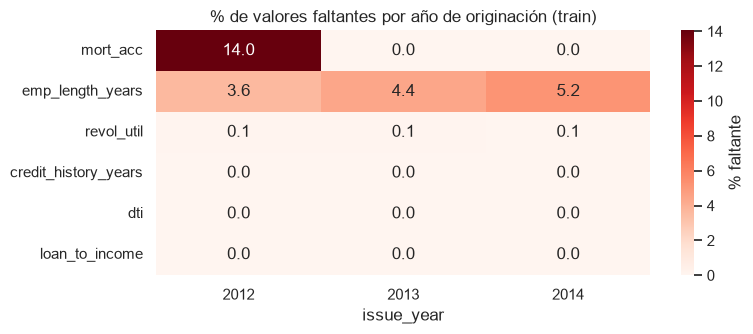

In [22]:
cols_na = ["mort_acc", "emp_length_years", "revol_util", "credit_history_years", "dti", "loan_to_income"]
faltantes_anio = train.groupby("issue_year")[cols_na].agg(lambda s: s.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(faltantes_anio.T, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% faltante"}, ax=ax)
ax.set_title("% de valores faltantes por año de originación (train)")
plt.tight_layout()
plt.show()


Si un campo tiene faltantes concentrados en ciertos años (por ejemplo, variables que Lending Club empezó a capturar más tarde),
el faltante es **informativo** y no aleatorio. Por eso el preprocesador agrega indicadores de faltante (`add_indicator=True`).


## 6. Outliers: winsorización ajustada solo con train

In [23]:
cols = ["annual_inc", "revol_bal", "loan_to_income"]
w = features.Winsorizer(columns=cols).fit(train)
antes = train[cols].describe(percentiles=[.5, .99, .995]).T[["50%", "99%", "99.5%", "max"]]
despues = w.transform(train[cols]).describe().T[["max"]].rename(columns={"max": "max (recortado)"})
pd.concat([antes, despues], axis=1)


,50%,99%,99.5%,max,max (recortado)
annual_inc,63000.000000,241000.000000,300000.000000,7.500000e+06,300000.000000
revol_bal,11906.000000,80924.430000,115501.810000,2.568995e+06,115501.810000
loan_to_income,0.208333,0.454677,0.479603,7.125000e-01,0.479603


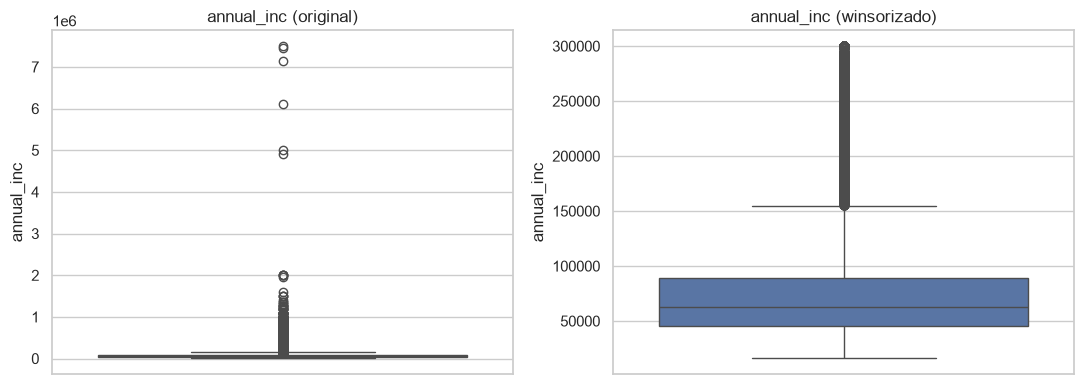

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(y=train["annual_inc"], ax=axes[0]); axes[0].set_title("annual_inc (original)")
sns.boxplot(y=w.transform(train[cols])["annual_inc"], ax=axes[1]); axes[1].set_title("annual_inc (winsorizado)")
plt.tight_layout()
plt.show()


Los cuantiles de recorte (0.5 % y 99.5 %) se aprenden en train y se aplican igual a validación y test.


## 7. Señal de las variables nuevas (solo train)

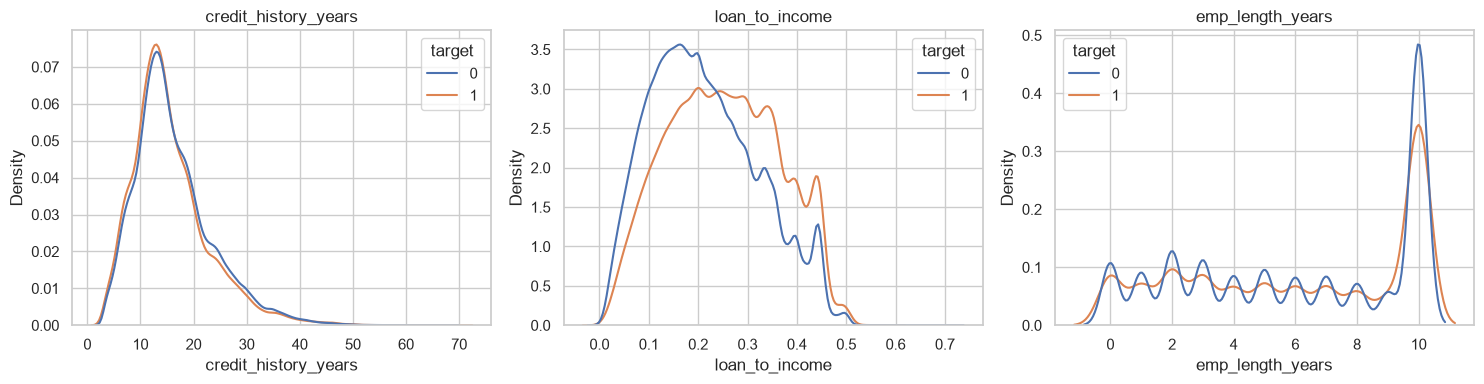

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["credit_history_years", "loan_to_income", "emp_length_years"]):
    sns.kdeplot(data=train, x=col, hue="target", common_norm=False, ax=ax, warn_singular=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()


## 8. Estabilidad entre conjuntos (solo features, sin mirar el target del test)

In [26]:
num, cat = features.get_feature_lists()
comparacion = pd.DataFrame({
    "train": train[num].mean(),
    "valid": valid[num].mean(),
    "test": test[num].mean(),
})
comparacion["dif. valid vs train (%)"] = ((comparacion["valid"] / comparacion["train"]) - 1) * 100
comparacion.round(3)


,train,valid,test,dif. valid vs train (%)
loan_amnt,14478.215,14641.618,14467.039,1.129
term_months,42.116,41.913,40.974,-0.484
annual_inc,73490.901,76269.696,78785.733,3.781
dti,17.536,18.936,18.727,7.984
fico_avg,696.455,695.517,697.301,-0.135
open_acc,11.345,11.880,11.886,4.713
total_acc,25.333,25.429,24.920,0.377
revol_bal,16267.175,17117.776,16359.761,5.229
revol_util,56.731,53.111,49.459,-6.381
delinq_2yrs,0.296,0.346,0.350,17.120


Diferencias grandes en una variable entre train y test son señal de *drift* en los datos de entrada. Se documentan como limitación.


## 9. Preprocesador (ajustado solo con train)

In [27]:
prep = features.build_preprocessor(include_grey_zone=False)
X_train = prep.fit_transform(train[num + cat])   # fit SOLO con train
X_valid = prep.transform(valid[num + cat])
X_test = prep.transform(test[num + cat])

print("Shapes:", X_train.shape, X_valid.shape, X_test.shape)
print("NaN restantes en valid:", int(np.isnan(X_valid).sum()))
print("Nº de features finales:", len(prep.get_feature_names_out()))
list(prep.get_feature_names_out())[:15]


Shapes: (411274, 30) (375546, 30) (293105, 30)
NaN restantes en valid: 0
Nº de features finales: 30


['loan_amnt',
 'term_months',
 'annual_inc',
 'dti',
 'fico_avg',
 'open_acc',
 'total_acc',
 'revol_bal',
 'revol_util',
 'delinq_2yrs',
 'inq_last_6mths',
 'pub_rec',
 'mort_acc',
 'emp_length_years',
 'credit_history_years']

## 10. Guardar los splits procesados

In [28]:
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
for nombre, d in {"train": train, "valid": valid, "test": test}.items():
    d.to_parquet(config.DATA_PROCESSED / f"{nombre}.parquet", index=False)
print("Guardado en", config.DATA_PROCESSED)


Guardado en C:\Users\JOSSEMY-PC\ProyectosVSC\proyecto-ML\data\processed


## 11. Decisiones y conclusiones

### Decisiones tomadas

**1. División temporal de los datos:** Se decidió utilizar los años 2012–2014 para entrenamiento (411,274 registros), 2015 para validación (375,546 registros) y 2016 para test (293,105 registros). Esta división permite evaluar los modelos con datos posteriores al entrenamiento, evitando una separación aleatoria que mezcle información de diferentes periodos.
Sin embargo, se identificó una limitación de censura: en 2015 solo el 67.1% de los préstamos a 60 meses tenía un desenlace definitivo, porcentaje que disminuye al 54.8% en 2016. Esto puede introducir sesgo al considerar únicamente préstamos resueltos.

**2. Limpieza de valores incorrectos:** Se decidió conservar los registros y convertir los valores inválidos a `NaN` para imputarlos posteriormente. Se identificaron:

- 535 registros con `dti` fuera del rango permitido.
- 20 registros con `revol_util` superior al 150%.
- 361 registros con `annual_inc` menor o igual a cero.

**3. Tratamiento de outliers y faltantes:** Se aplicó winsorización entre los percentiles 0.5% y 99.5% para `annual_inc`, `revol_bal` y `loan_to_income`, los límites se calcularon exclusivamente con entrenamiento.
Los valores faltantes se tratan mediante imputación y se incorporan indicadores de ausencia para conservar información potencialmente relevante.

**4. Ingeniería y selección de variables:**
Se crearon variables como `fico_avg`, `credit_history_years`, `loan_to_income`, `term_months`, `emp_length_years` y `purpose_grouped`, utilizando información disponible al solicitar el préstamo.
Se excluyeron variables posteriores al resultado del préstamo para evitar fuga de información (*data leakage*). También se dejaron fuera variables como `emp_title` y `addr_region` de la configuración principal.

### Conclusiones

La limpieza permitió preparar un conjunto de datos consistente para el entrenamiento de modelos de clasificación. El preprocesamiento produjo **30 características finales, sin valores faltantes en la matriz de validación**.

El análisis mostró que algunas variables presentan diferencias entre los periodos. Por ejemplo, el DTI promedio aumentó aproximadamente 7.98% y `pub_rec` aumentó 40.54% entre entrenamiento y validación. Esto evidencia posibles cambios en las características de los solicitantes a través del tiempo.

Además, la variable `loan_to_income` mostró diferencias entre préstamos pagados e incumplidos, lo que sugiere que puede aportar información útil para predecir el riesgo crediticio.

Finalmente, los conjuntos quedaron preparados y almacenados para el entrenamiento. Aunque la división temporal reduce el riesgo de fuga de información, **la censura de préstamos aún no resueltos sigue siendo una limitación importante**, especialmente para el test de 2016.
